<a href="https://colab.research.google.com/github/Saad0047/Grid-World-Navigation-with-Q-Learning/blob/main/Grid_World_Navigation_with_Q_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Grid World Navigation with Q-Learning**

In [1]:
# Importing the necessary Libraries
import numpy as np

## **Defining the Environment**

### States

In [2]:
ROWS = 4
COLS = 4
START = (0, 0)           # where the agent begins
GOAL = (3, 3)            # where it wants to get to
WALLS = [(1, 1), (2, 3)] # cells it cannot enter

In [3]:
# A state is just a position (row, col).
# Two loops visit every cell and add it to a list.
states = []
for r in range(ROWS):
    for c in range(COLS):
        states.append((r, c))

print(states)
print("Total states:", len(states))

[(0, 0), (0, 1), (0, 2), (0, 3), (1, 0), (1, 1), (1, 2), (1, 3), (2, 0), (2, 1), (2, 2), (2, 3), (3, 0), (3, 1), (3, 2), (3, 3)]
Total states: 16


### Actions

In [4]:
# Each action number maps to (change in row, change in column)
ACTIONS = {
    0: (-1, 0),   # Up
    1: (1, 0),    # Down
    2: (0, -1),   # Left
    3: (0, 1),    # Right
}

# Names, only so our printed output is readable
ACTION_NAMES = {0: "Up", 1: "Down", 2: "Left", 3: "Right"}

N_ACTIONS = len(ACTIONS)
print("Number of actions:", N_ACTIONS)

Number of actions: 4


### Rewards

In [7]:
GOAL_REWARD = 10
STEP_REWARD = -1
WALL_REWARD = -2

# Helper: is this position a place the agent cannot go?
def is_blocked(r, c):
    outside_grid = r < 0 or r >= ROWS or c < 0 or c >= COLS
    hit_wall = (r, c) in WALLS
    return outside_grid or hit_wall

In [12]:
def step(state, action):
    change = ACTIONS[action]
    new_row = state[0] + change[0]
    new_col = state[1] + change[1]

    # wall or outside the grid -> stay in place, -2
    if is_blocked(new_row, new_col):
        return state, WALL_REWARD, False

    next_state = (new_row, new_col)

    # reached the goal -> +10, episode over
    if next_state == GOAL:
        return next_state, GOAL_REWARD, True

    # normal move -> -1
    return next_state, STEP_REWARD, False

## **Q-Table**

In [8]:
# Initialization
# shape = (rows, columns, actions) -> 4 x 4 x 4 = 64 numbers, all 0
Q = np.zeros((ROWS, COLS, N_ACTIONS))

## **Learning (Epsilon-Greedy + Q-Update)**

In [10]:
import random

alpha = 0.1      # learning rate
gamma = 0.9      # discount factor
epsilon = 0.1    # chance of exploring

def choose_action(state, epsilon):
    # Explore: random action
    if random.random() < epsilon:
        return random.randint(0, N_ACTIONS - 1)
    # Exploit: best known action
    return int(np.argmax(Q[state[0], state[1]]))


def update_q(state, action, reward, next_state, done):
  old_q = Q[state[0], state[1], action]
  if done:
      target = reward
  else:
      best_next = np.max(Q[next_state[0], next_state[1]])
      target = reward + gamma * best_next

  Q[state[0], state[1], action] = old_q + alpha * (target - old_q)

## **Training**

In [13]:
episodes = 500        # how many attempts
max_steps = 100       # safety limit per attempt
rewards_per_episode = []

for episode in range(episodes):
    state = START
    total_reward = 0

    for _ in range(max_steps):
        action = choose_action(state, epsilon)
        next_state, reward, done = step(state, action)
        update_q(state, action, reward, next_state, done)

        state = next_state
        total_reward += reward

        if done:
            break

    rewards_per_episode.append(total_reward)

print("Training finished")

Training finished


In [14]:
# Check progress: average reward of every block of 100 episodes
for i in range(0, episodes, 100):
    block = rewards_per_episode[i:i+100]
    print("Episodes", i, "-", i + 99, ": average reward =", round(sum(block) / len(block), 1))

Episodes 0 - 99 : average reward = 0.8
Episodes 100 - 199 : average reward = 4.0
Episodes 200 - 299 : average reward = 4.2
Episodes 300 - 399 : average reward = 4.4
Episodes 400 - 499 : average reward = 4.0


## **Results**

In [15]:
print("Learned Q-table (columns: Up, Down, Left, Right)\n")
for r in range(ROWS):
    for c in range(COLS):
        if (r, c) in WALLS:
            print((r, c), "WALL")
        else:
            print((r, c), np.round(Q[r, c], 2))

Learned Q-table (columns: Up, Down, Left, Right)

(0, 0) [-0.82  1.81 -0.88 -1.61]
(0, 1) [-1.51 -1.54 -1.55  0.27]
(0, 2) [-0.98  3.13 -0.88 -0.85]
(0, 3) [-0.79 -0.75 -0.72 -1.11]
(1, 0) [-0.1   3.12 -0.44  0.07]
(1, 1) WALL
(1, 2) [-0.44  6.01  0.09 -0.59]
(1, 3) [-0.69 -0.78 -0.66 -0.78]
(2, 0) [0.77 0.58 1.58 4.58]
(2, 1) [2.42 2.85 1.92 6.2 ]
(2, 2) [2.81 8.   2.71 3.5 ]
(2, 3) WALL
(3, 0) [ 0.26 -0.38 -0.39  3.86]
(3, 1) [ 0.28  0.29 -0.21  7.91]
(3, 2) [ 3.59  5.16  4.8  10.  ]
(3, 3) [0. 0. 0. 0.]


In [16]:
# epsilon = 0 -> no exploring, always pick the best action
state = START
path = [state]

for _ in range(max_steps):
    action = int(np.argmax(Q[state[0], state[1]]))
    state, reward, done = step(state, action)
    path.append(state)
    if done:
        break

print("Path:", path)
print("Steps taken:", len(path) - 1)

Path: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (3, 2), (3, 3)]
Steps taken: 6


In [17]:
grid = [["." for _ in range(COLS)] for _ in range(ROWS)]
for r, c in WALLS:
    grid[r][c] = "#"
for r, c in path:
    grid[r][c] = "*"
grid[START[0]][START[1]] = "S"
grid[GOAL[0]][GOAL[1]] = "G"

for row in grid:
    print(" ".join(row))

S . . .
* # . .
* * * #
. . * G


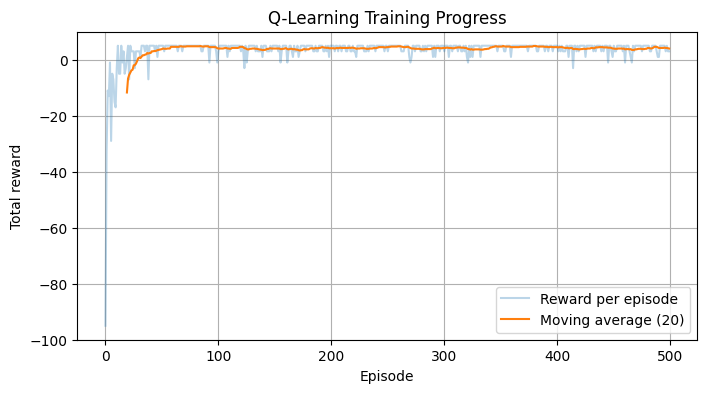

In [18]:
import matplotlib.pyplot as plt

# smooth with a moving average of 20 episodes so the trend is visible
window = 20
smooth = np.convolve(rewards_per_episode, np.ones(window) / window, mode="valid")

plt.figure(figsize=(8, 4))
plt.plot(rewards_per_episode, alpha=0.3, label="Reward per episode")
plt.plot(range(window - 1, len(rewards_per_episode)), smooth, label="Moving average (20)")
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.title("Q-Learning Training Progress")
plt.legend()
plt.grid(True)
plt.savefig("reward_graph.png")
plt.show()